In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc, recall_score
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
df_train = pd.read_excel("两年训练集过采样.xlsx")
print(df_train.head())

In [ ]:
df_test = pd.read_excel("73平衡测试集.xlsx")
print(df_test.head())

In [4]:
X_train = df_train.drop('com_endow', axis = 1)
y_train = df_train['com_endow']

X_test = df_test.drop('com_endow', axis = 1)
y_test = df_test['com_endow']

In [5]:
# 初始化随机森林分类器
rf = RandomForestClassifier(random_state=77, class_weight={0: 1, 1: 5}) 

# 设置超参数网格
param_grid = {
    'n_estimators': [50, 100, 150],  # 树的数量
    'max_depth': [None, 10, 20, 30],  # 最大深度
    'min_samples_split': [2, 5, 10],  # 最小分裂样本数
    'min_samples_leaf': [1, 2, 4]  # 最小叶节点样本数
}


In [6]:
# 初始化GridSearchCV以进行超参数优化
# 5折交叉验证
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, n_jobs=-1, verbose=0, scoring='recall')

# 训练模型
grid_search.fit(X_train, y_train)

# 输出最佳参数
print("Best Parameters:", grid_search.best_params_)


Best Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 50}


In [7]:
# 使用最佳参数预测测试集
best_model = grid_search.best_estimator_

# 获取正类的概率
y_prob = best_model.predict_proba(X_test)[:, 1]

#y_pred = best_model.predict(X_test)
y_pred = (y_prob > 0.5).astype(int)
# 评估模型性能
print("Test Set Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Test Set Accuracy: 0.7138364779874213
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.78      0.79       445
           1       0.52      0.55      0.54       191

    accuracy                           0.71       636
   macro avg       0.66      0.67      0.67       636
weighted avg       0.72      0.71      0.72       636



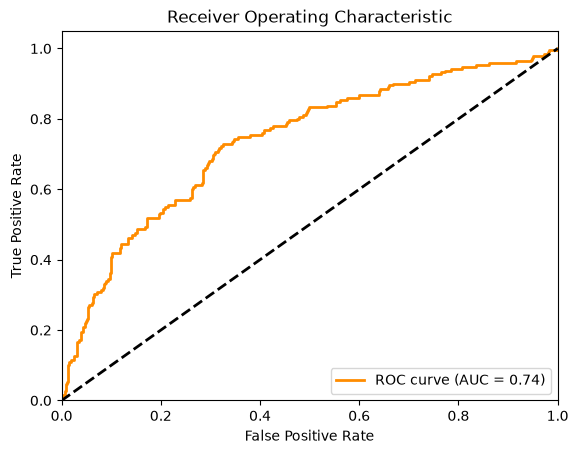

In [8]:
# 获取正类的概率
y_prob = best_model.predict_proba(X_test)[:, 1]

# 计算 ROC 曲线和 AUC
fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label=1)
roc_auc = auc(fpr, tpr)

# 绘制 ROC 曲线
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:0.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)  # 绘制 y=x 的参考线
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()